In [1]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
# Path to your .ttf
font_path = "/home/links/mf671/times.ttf"

# Add the font to Matplotlib's font manager
fm.fontManager.addfont(font_path)

# Get the name of the font inside the .ttf
font_name = fm.FontProperties(fname=font_path).get_name()

# Set as default
plt.rcParams['font.family'] = font_name
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
import numpy as np
from tqdm import tqdm
import cftime
from dask.diagnostics import ProgressBar

In [2]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + ds_sh.time.values[-1].year, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [3]:
ProgressBar().register()

# Path to data and experiments
base_path = '/home/links/mf671/DATA/isca_data'
experiments = [
    'exeter_project_mf_baseline_KS',
    'exeter_project_mf_aa_KS_30_72,90',
    'exeter_project_mf_baseline_st_KS',
    'exeter_project_mf_aa_st_KS_30_72,90'
]

# Load datasets
ds_clims = []
compute_climatology = False
if compute_climatology:
    for experiment in experiments:
        print(experiment)
        print(f'{base_path}/{experiment}/tot/TKE_monthly_2.5x2.5_2-51.nc')
        tke = flip_and_append(xr.open_mfdataset(f'{base_path}/{experiment}/tot/TKE_monthly_2.5x2.5_2-51.nc',
                                                parallel=True,
                                                chunks={'time': 30}))['tke'].loc[:,250,:,:].mean('time')
        tke_std = (flip_and_append(xr.open_mfdataset(f'{base_path}/{experiment}/tot/TKE_monthly_2.5x2.5_2-51.nc',
                                                parallel=True,
                                                chunks={'time': 30}))['tke'].loc[:,250,:,:].std('time')/np.sqrt(2*12*50)).rename('tke_std')
        dw_lwa = xr.open_mfdataset(f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc',
                                parallel=True,
                                chunks={'time': 30})['dw_lwa'].mean('time')
        dw_lwa_std = (xr.open_mfdataset(f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc',
                                parallel=True,
                                chunks={'time': 30})['dw_lwa'].std('time')/np.sqrt(2*365*50)).rename('dw_lwa_std')
        print(tke_std.shape,tke.shape,dw_lwa_std.shape,dw_lwa.shape)
        ds = xr.merge([tke,dw_lwa,tke_std,dw_lwa_std])
        ds.to_netcdf(f'{base_path}/{experiment}/TKE_dw_lwa_CLIM_1.5x1.5.nc')
        ds_clims.append(ds)
else:
    for experiment in experiments:
        ds = xr.open_dataset(f'{base_path}/{experiment}/TKE_dw_lwa_CLIM_1.5x1.5.nc')
        ds_clims.append(ds)

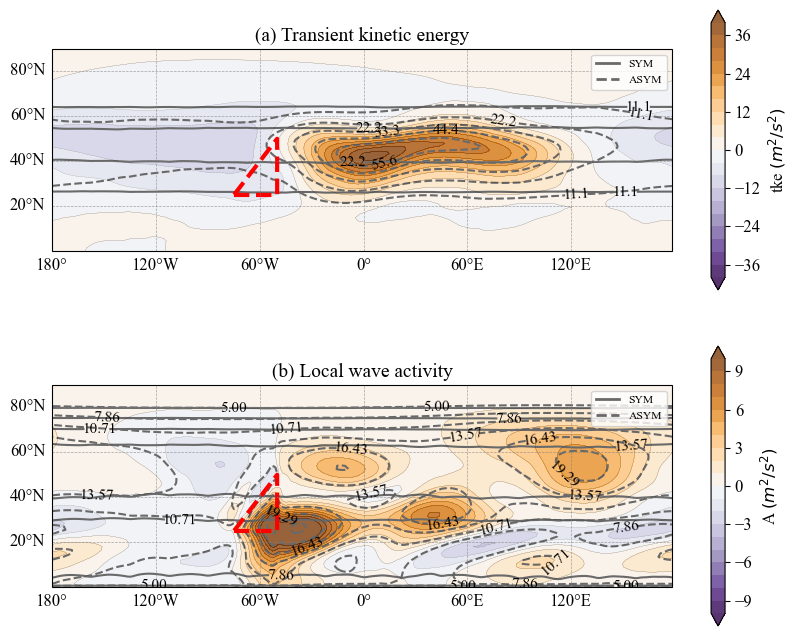

In [4]:
from matplotlib.lines import Line2D 

# Set global font family and size
plt.rcParams['font.family'] = 'Times New Roman'      # e.g., 'serif', 'sans-serif', 'monospace'
plt.rcParams['font.size'] = 12             # default font size

# Initialize a 2-axis figure with Cartopy projection
fig, ax = plt.subplots(2, 1, figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})

#triangle coordinates
coords = [
    (-75.0, 25.0),  # Point A
    (-50.0, 25.0),  # Point B
    (-50.0, 50.0)   # Point C
]
# Unzip into separate lists of longitudes and latitudes, and close the triangle
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

custom_lines = [
    Line2D([0], [0], color='dimgray', lw=2, linestyle='solid', label='SYM'),
    Line2D([0], [0], color='dimgray', lw=2, linestyle='dashed', label='ASYM')
]

# Plot TKE contour for baseline st and baseline on the first axis
levels = np.linspace(0, 100, 10)
levels_diff = np.linspace(-40, 40, 21)
ax[0].set_title('(a) Transient kinetic energy')
c1 = ax[0].contour(ds_clims[0]['lon'], ds_clims[0]['lat'], ds_clims[0]['tke'], levels=levels, alpha = 1, colors='dimgray', transform=ccrs.PlateCarree())
ax[0].clabel(c1, inline=True, colors = 'black', inline_spacing = 1,rightside_up=True ,fontsize=11)
c2 = ax[0].contour(ds_clims[2]['lon'], ds_clims[2]['lat'], ds_clims[2]['tke'], levels=levels, alpha = 1, colors='dimgray', linestyles='dashed', transform=ccrs.PlateCarree())
ax[0].clabel(c2, inline=True, colors = 'black', inline_spacing = 1,rightside_up=True ,fontsize=11)
sh = ax[0].contourf(ds_clims[0]['lon'], ds_clims[0]['lat'], ds_clims[2]['tke'] - ds_clims[0]['tke'], levels=levels_diff, cmap='PuOr_r', alpha=0.8, extend='both', transform=ccrs.PlateCarree())
cont = ax[0].contour(ds_clims[0]['lon'], ds_clims[0]['lat'], ds_clims[2]['tke'] - ds_clims[0]['tke'], levels=levels_diff, colors = 'k', linewidths= 0.1, transform=ccrs.PlateCarree())
fig.colorbar(sh, ax=ax[0], orientation='vertical', label='tke $(m^2/s^2)$')
ax[0].plot(lons, lats, linestyle='--',linewidth=3, color='red', transform=ccrs.PlateCarree())
ax[0].set_aspect(1.3)

#add legend
ax[0].legend(handles=custom_lines, loc='upper right',fontsize='x-small')

# Add hatchings for significance
significance = np.abs(ds_clims[2]['tke'] - ds_clims[0]['tke']) > np.sqrt(ds_clims[0]['tke_std']**2 + ds_clims[2]['tke_std']**2)
#ax[0].contourf(ds_clims[0]['lon'], ds_clims[0]['lat'], significance, levels=[0.5, 1], hatches=['...', None], colors='none', transform=ccrs.PlateCarree())

# Add gridlines to the first axis
gl0 = ax[0].gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
gl0.top_labels = False
gl0.right_labels = False

# Plot the dw_lwa zonal mean on the second axis
levels = np.linspace(5, 25, 8)
levels_diff = np.linspace(-10, 10, 21)
ax[1].set_title('(b) Local wave activity')
c3 = ax[1].contour(ds_clims[0]['lon'], ds_clims[0]['lat'], ds_clims[0]['dw_lwa'], levels=levels, colors='dimgray', transform=ccrs.PlateCarree())
ax[1].clabel(c3, inline=True, colors = 'black', inline_spacing = 1,rightside_up=True ,fontsize=11)
c4 = ax[1].contour(ds_clims[2]['lon'], ds_clims[2]['lat'], ds_clims[2]['dw_lwa'], levels=levels, colors='dimgray', linestyles = 'dashed', transform=ccrs.PlateCarree())
ax[1].clabel(c4, inline=True, colors = 'black', inline_spacing = 1,rightside_up=True ,fontsize=11)
sh2 = ax[1].contourf(ds_clims[0]['lon'], ds_clims[0]['lat'], ds_clims[2]['dw_lwa'] - ds_clims[0]['dw_lwa'], levels=levels_diff, cmap='PuOr_r', alpha=0.8, extend='both', transform=ccrs.PlateCarree())
cont2 = ax[1].contour(ds_clims[0]['lon'], ds_clims[0]['lat'], ds_clims[2]['dw_lwa'] - ds_clims[0]['dw_lwa'], levels=levels_diff, colors = 'k', linewidths = 0.1)
fig.colorbar(sh2, ax=ax[1], orientation='vertical', label='A $(m^2/s^2)$')
ax[1].plot(lons, lats, linestyle='--',linewidth=3, color='red', transform=ccrs.PlateCarree())
ax[1].set_aspect(1.3)

#add legend
ax[1].legend(handles=custom_lines, loc='upper right',fontsize='x-small')

# Add hatchings for significance
significance2 = np.abs(ds_clims[2]['dw_lwa'] - ds_clims[0]['dw_lwa']) > np.sqrt(ds_clims[0]['dw_lwa_std']**2 + ds_clims[2]['dw_lwa_std']**2)
#ax[1].contourf(ds_clims[0]['lon'], ds_clims[0]['lat'], significance2, levels=[0.5, 1], hatches=['...', None], colors='none', transform=ccrs.PlateCarree())

# Add gridlines to the second axis
gl1 = ax[1].gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
gl1.top_labels = False
gl1.right_labels = False

plt.savefig('PLOTS/Figure2.png',dpi=300)

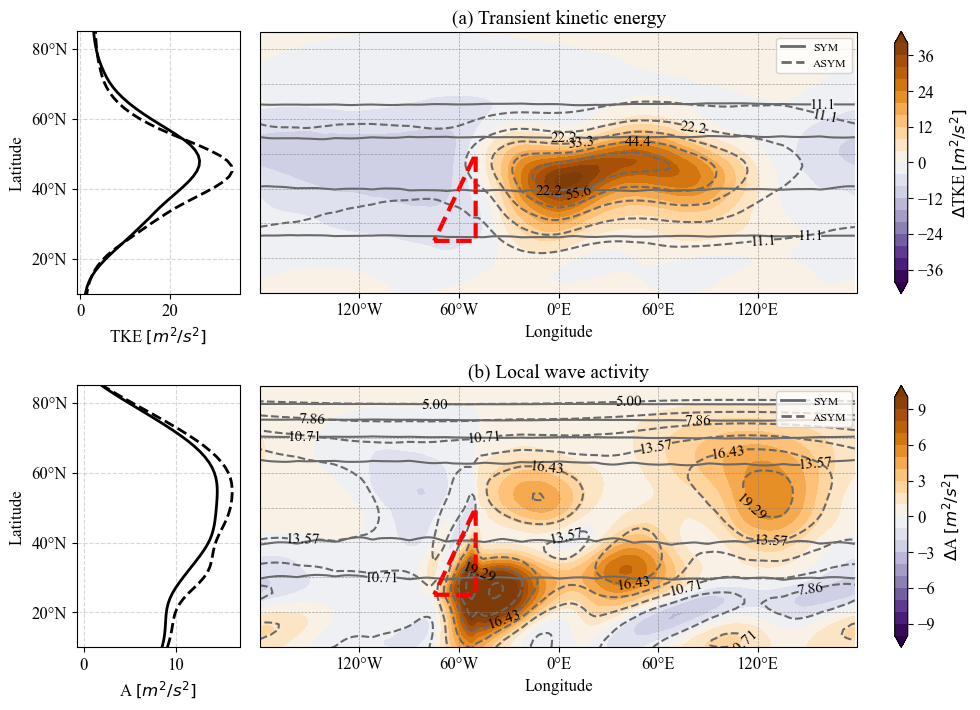

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
from matplotlib.lines import Line2D

# --------------------------------------------------
# Global settings
# --------------------------------------------------
#plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 12

# --------------------------------------------------
# Figure + GridSpec
# --------------------------------------------------
fig = plt.figure(figsize=(12, 8))

# | xsec | gap | map |
gs = gridspec.GridSpec(
    nrows=2,
    ncols=3,
    width_ratios=[1.2, 0.15, 5.5],
    hspace=0.35,
    wspace=0.0
)

# --------------------------------------------------
# Triangle coordinates
# --------------------------------------------------
coords = [(-75, 25), (-50, 25), (-50, 50)]
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

# --------------------------------------------------
# Legend handles
# --------------------------------------------------
custom_lines = [
    Line2D([0], [0], color='dimgray', lw=2, linestyle='solid', label='SYM'),
    Line2D([0], [0], color='dimgray', lw=2, linestyle='dashed', label='ASYM')
]

# --------------------------------------------------
# Common map settings
# --------------------------------------------------
lonmin = float(ds_clims[0].lon.min())
lonmax = float(ds_clims[0].lon.max())

xticks = [-120, -60, 0, 60, 120]
xtick_labels = ['120°W', '60°W', '0°E', '60°E', '120°E']

# ==================================================
# ROW 1 — TKE
# ==================================================
ax_xsec = fig.add_subplot(gs[0, 0])
ax_map  = fig.add_subplot(gs[0, 2],
                          projection=ccrs.PlateCarree(),
                          sharey=ax_xsec)

# ---- Map ----
levels = np.linspace(0, 100, 10)
levels_diff = np.linspace(-40, 40, 21)

ax_map.set_title('(a) Transient kinetic energy')

c1 = ax_map.contour(ds_clims[0].lon, ds_clims[0].lat, ds_clims[0].tke,
                    levels=levels, colors='dimgray')
c2 = ax_map.contour(ds_clims[2].lon, ds_clims[2].lat, ds_clims[2].tke,
                    levels=levels, colors='dimgray', linestyles='dashed')

ax_map.clabel(c1,  inline=True, colors = 'black', inline_spacing = 1,rightside_up=True ,fontsize=11)
ax_map.clabel(c2,  inline=True, colors = 'black', inline_spacing = 1,rightside_up=True ,fontsize=11)

sh = ax_map.contourf(ds_clims[0].lon, ds_clims[0].lat,
                     ds_clims[2].tke - ds_clims[0].tke,
                     levels=levels_diff, cmap='PuOr_r', extend='both')

fig.colorbar(sh, ax=ax_map, label=r'$\Delta$TKE $[m^2/s^2]$')

ax_map.plot(lons, lats, '--', lw=3, color='red',
            transform=ccrs.PlateCarree())

ax_map.set_extent([lonmin, lonmax, 10, 85])
ax_map.set_aspect(2.1)
ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
ax_map.set_xticklabels(xtick_labels)
ax_map.set_xlabel('Longitude')

ax_map.legend(handles=custom_lines, loc='upper right', fontsize='x-small')

ax_map.gridlines(draw_labels=False, linewidth=0.5,
                 color='gray', alpha=0.7, linestyle='--')

# ---- Cross-section ----
#tke_xsec = (ds_clims[2].tke - ds_clims[0].tke).mean('lon')

ax_xsec.plot(ds_clims[2].tke.mean('lon'), ds_clims[0].lat, color='k', linestyle = 'dashed' ,lw=2)
ax_xsec.plot(ds_clims[0].tke.mean('lon'), ds_clims[0].lat, color='k', linestyle = 'solid' , lw=2)
#ax_xsec.axvline(0, color='gray', ls='--')
ax_xsec.set_xlabel(r'TKE $[m^2/s^2]$')
ax_xsec.set_ylabel('Latitude')
ax_xsec.grid(True, ls='--', alpha=0.5)
ax_xsec.set_yticks([20, 40, 60, 80])
ax_xsec.set_yticklabels(['20°N', '40°N', '60°N', '80°N'])
#ax_xsec.set_xlim((-9,9))

plt.setp(ax_map.get_yticklabels(), visible=False)

# ==================================================
# ROW 2 — LWA
# ==================================================
ax_xsec = fig.add_subplot(gs[1, 0])
ax_map  = fig.add_subplot(gs[1, 2],
                          projection=ccrs.PlateCarree(),
                          sharey=ax_xsec)

levels = np.linspace(5, 25, 8)
levels_diff = np.linspace(-10, 10, 21)

ax_map.set_title('(b) Local wave activity')

c1 = ax_map.contour(ds_clims[0].lon, ds_clims[0].lat, ds_clims[0].dw_lwa,
                    levels=levels, colors='dimgray')
c2 = ax_map.contour(ds_clims[2].lon, ds_clims[2].lat, ds_clims[2].dw_lwa,
                    levels=levels, colors='dimgray', linestyles='dashed')

ax_map.clabel(c1,  inline=True, colors = 'black', inline_spacing = 1,rightside_up=True ,fontsize=11)
ax_map.clabel(c2,  inline=True, colors = 'black', inline_spacing = 1,rightside_up=True ,fontsize=11)

sh = ax_map.contourf(ds_clims[0].lon, ds_clims[0].lat,
                     ds_clims[2].dw_lwa - ds_clims[0].dw_lwa,
                     levels=levels_diff, cmap='PuOr_r', extend='both')

fig.colorbar(sh, ax=ax_map, label=r'$\Delta$A $[m^2/s^2]$')

ax_map.plot(lons, lats, '--', lw=3, color='red',
            transform=ccrs.PlateCarree())

ax_map.set_extent([lonmin, lonmax, 10, 85])
ax_map.set_aspect(2.1)
ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
ax_map.set_xticklabels(xtick_labels)
ax_map.set_xlabel('Longitude')

ax_map.legend(handles=custom_lines, loc='upper right', fontsize='x-small')

ax_map.gridlines(draw_labels=False, linewidth=0.5,
                 color='gray', alpha=0.7, linestyle='--')

# ---- Cross-section ----
#lwa_xsec = (ds_clims[2].dw_lwa - ds_clims[0].dw_lwa).mean('lon')

ax_xsec.plot(ds_clims[2].dw_lwa.mean('lon'), ds_clims[0].lat, color='k', linestyle = 'dashed' ,lw=2)
ax_xsec.plot(ds_clims[0].dw_lwa.mean('lon'), ds_clims[0].lat, color='k', linestyle = 'solid' , lw=2)
#ax_xsec.axvline(0, color='gray', ls='--')
ax_xsec.set_xlabel(r'A $[m^2/s^2]$')
ax_xsec.set_ylabel('Latitude')
ax_xsec.grid(True, ls='--', alpha=0.5)
ax_xsec.set_yticks([20, 40, 60, 80])
ax_xsec.set_yticklabels(['20°N', '40°N', '60°N', '80°N'])
#ax_xsec.set_xlim((-2.5,2.5))

plt.setp(ax_map.get_yticklabels(), visible=False)

# --------------------------------------------------
plt.savefig('PLOTS/Figure2_with_xsec.png',
            dpi=300, bbox_inches='tight')
plt.show()